# ` Intelligent E-Commerce Customer Analytics Platform `

## Objectives
- Answer business questions such as:

    - 1. Why is this customer likely to purchase again?
    - 2. Which features contribute most to Customer Lifetime Value?
    - 3. Why did the model make this prediction?

# Step 1 – Install SHAP

In [2]:
!pip3 install shap

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Step 2 – Import Libraries

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import shap
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split

shap.initjs()
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer


import warnings
warnings.filterwarnings("ignore")



# Step 3 – Prepare the Modeling Dataset

In [4]:
customer_df = pd.read_csv("../data/processed/customer_analytics_featured.csv")
customer_df.head() 

# Convert purchase Date
customer_df["order_purchase_timestamp"] = pd.to_datetime(
    customer_df["order_purchase_timestamp"]
)

# Sort Customer Purchase
customer_df = customer_df.sort_values(
    ["customer_unique_id", "order_purchase_timestamp"]
)

# Find Next Purchase Date
customer_df["Next_Purchase_Date"] = (
    customer_df.groupby("customer_unique_id")["order_purchase_timestamp"]
               .shift(-1)
)

# Calculate Days Until Next Purchase
customer_df["Days_To_Next_Purchase"] = (
    customer_df["Next_Purchase_Date"]
    - customer_df["order_purchase_timestamp"]
).dt.days

# Create Target Variable
customer_df["Repeat_Purchase"] = np.where(
    customer_df["Days_To_Next_Purchase"] <= 90,
    1,
    0
)

# Handle Last Purchase
    # Customers with no future purchase have NaN for Days_To_Next_Purchase.

customer_df["Repeat_Purchase"] = (
    customer_df["Repeat_Purchase"]
    .fillna(0)
    .astype(int)
)

# Target Distribution
customer_df["Repeat_Purchase"].value_counts()




# Remove Leakage Columns

drop_columns = [

    # IDs
    "customer_id",
    "customer_unique_id",
    "order_id",
    "review_id",
    "product_id",
    "seller_id",

    # Free text
    "review_comment_title",
    "review_comment_message",

    # Raw timestamps
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_customer_date",
    "order_delivered_carrier_date",
    "order_estimated_delivery_date",
    "shipping_limit_date",
    "review_creation_date",
    "review_answer_timestamp",

    # Leakage
    "Next_Purchase_Date",
    "Days_To_Next_Purchase",
    "Repeat_Purchase"
]

X = customer_df.drop(columns=drop_columns)
y = customer_df["Repeat_Purchase"]

# Step 4 – Explain the Repeat Purchase Prediction Model (LightGBM)

In [5]:
# Load Saved Model & Preprocessor
loaded_model = joblib.load("../artifacts/lightgbm_repeat_purchase_model.pkl")
preprocessor = joblib.load("../artifacts/preprocessor.pkl")
model = loaded_model

# Identify Feature Types
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
print("Numerical Features :", len(numeric_features))
print("Categorical Features :", len(categorical_features))

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

# Transform the Data
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape :", X_train_processed.shape)
print("Processed Testing Shape  :", X_test_processed.shape)

Numerical Features : 25
Categorical Features : 12
Training Shape : (95314, 37)
Testing Shape  : (23829, 37)
Processed Training Shape : (95314, 8735)
Processed Testing Shape  : (23829, 8735)


In [6]:
# ============================================================
# STEP – Generate and Save SHAP Artifacts
# ============================================================

import shap
import joblib
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. Load saved model and preprocessor
# ------------------------------------------------------------

loaded_model = joblib.load(
    "../artifacts/lightgbm_repeat_purchase_model.pkl"
)

preprocessor = joblib.load(
    "../artifacts/preprocessor.pkl"
)

print("Model loaded successfully.")
print("Preprocessor loaded successfully.")


# ------------------------------------------------------------
# 2. Transform test data
# ------------------------------------------------------------

X_test_processed = preprocessor.transform(X_test)

print(
    "Processed Test Shape:",
    X_test_processed.shape
)


# ------------------------------------------------------------
# 3. Get transformed feature names
# ------------------------------------------------------------

feature_names = (
    preprocessor
    .get_feature_names_out()
)

print(
    "Number of Feature Names:",
    len(feature_names)
)

print(
    "First 10 Feature Names:"
)

print(
    feature_names[:10]
)


# ------------------------------------------------------------
# 4. Take the same 500-row sample used in Phase 9
# ------------------------------------------------------------

X_sample = X_test_processed[:500].toarray()

print(
    "SHAP Sample Shape:",
    X_sample.shape
)


# ------------------------------------------------------------
# 5. Create SHAP Explainer
# ------------------------------------------------------------

explainer = shap.Explainer(
    loaded_model
)


# ------------------------------------------------------------
# 6. Calculate SHAP values
# ------------------------------------------------------------

shap_values_sample = explainer(
    X_sample
)

# Assign transformed feature names
shap_values_sample.feature_names = list(
    feature_names
)

print(
    "SHAP values generated successfully."
)

print(
    "SHAP Value Shape:",
    shap_values_sample.values.shape
)


# ------------------------------------------------------------
# 7. Create artifacts directory if required
# ------------------------------------------------------------

artifacts_path = Path("../artifacts")

artifacts_path.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 8. Save SHAP Explanation object
# ------------------------------------------------------------

joblib.dump(
    shap_values_sample,
    artifacts_path / "shap_values_sample.pkl"
)


# ------------------------------------------------------------
# 9. Save feature names separately
# ------------------------------------------------------------

joblib.dump(
    list(feature_names),
    artifacts_path / "shap_feature_names.pkl"
)


# ------------------------------------------------------------
# 10. Save SHAP sample data
# ------------------------------------------------------------

np.save(
    artifacts_path / "shap_sample.npy",
    X_sample
)


print("\n===================================")
print("SHAP ARTIFACTS SAVED SUCCESSFULLY")
print("===================================")

print(
    "shap_values_sample.pkl"
)

print(
    "shap_feature_names.pkl"
)

print(
    "shap_sample.npy"
)

Model loaded successfully.
Preprocessor loaded successfully.
Processed Test Shape: (23829, 8735)
Number of Feature Names: 8735
First 10 Feature Names:
['num__customer_zip_code_prefix' 'num__order_item_id' 'num__price'
 'num__freight_value' 'num__product_name_lenght'
 'num__product_description_lenght' 'num__product_photos_qty'
 'num__product_weight_g' 'num__product_length_cm' 'num__product_height_cm']
SHAP Sample Shape: (500, 8735)
SHAP values generated successfully.
SHAP Value Shape: (500, 8735)

SHAP ARTIFACTS SAVED SUCCESSFULLY
shap_values_sample.pkl
shap_feature_names.pkl
shap_sample.npy


# Step 5 – Create SHAP Explainer

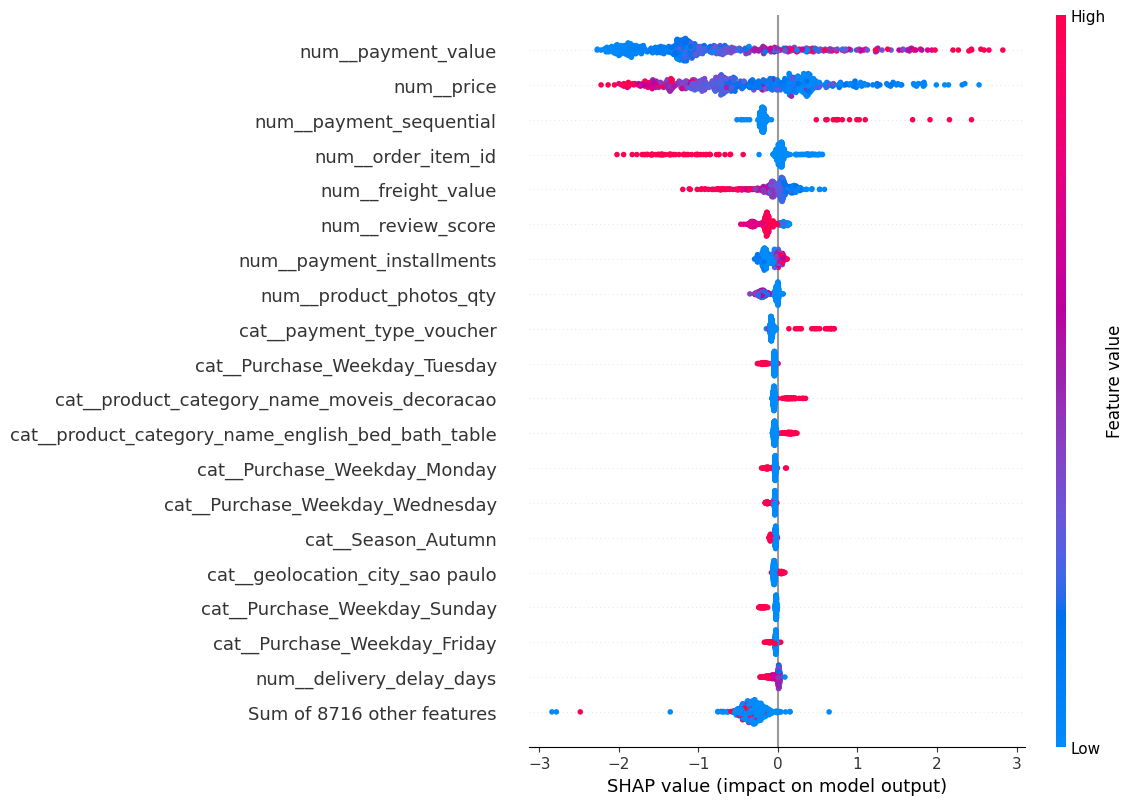

In [7]:

# Take a small sample
X_sample = X_test_processed[:500].toarray()
explainer = shap.Explainer(loaded_model)
shap_values_sample = explainer(X_sample)

# Assign the original feature names
shap_values_sample.feature_names = list(feature_names)
shap.plots.beeswarm(shap_values_sample, max_display=20)

- From your plots, the most influential features are:

- Rank	Feature	             Business Meaning
- 1	Payment Value          	Higher spending strongly influences customer behavior.
- 2	Price	                Product price affects repeat purchase decisions.
- 3	Payment Sequential	    Multiple payment records influence purchasing patterns.
- 4	Order Item ID	        Larger orders contribute to customer engagement.
- 5	Freight Value	        Shipping cost impacts customer satisfaction and repurchase.
- 6	Review Score	        Better reviews encourage repeat purchases.
- 7	Payment Installments	Installment choices affect buying decisions.
- 8	Product Photos	        Better product presentation can influence future purchases.

## Business interpretation:
- Customers with higher spending, favorable pricing, good review scores, and positive purchasing experiences are generally more likely to become repeat customers.
- This plot shows:
    - 1. Most influential features
    - 2. Direction of influence (positive or negative)
    - 3. Distribution of SHAP values
- It answers:
    - Which features contribute most to customer value?

# Step 6 – SHAP Waterfall Plot

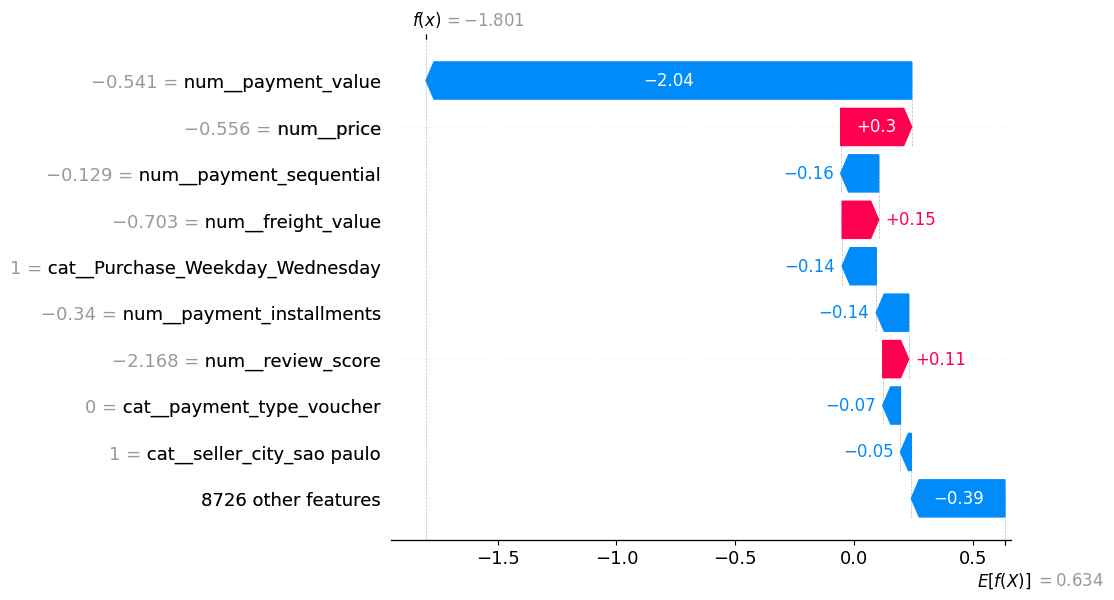

In [8]:
customer_index = 0
shap.plots.waterfall(shap_values_sample[customer_index])

- It answers:
    - Why is this specific customer predicted to purchase again?

- The waterfall plot shows which features push the prediction higher or lower relative to the baseline

# Step 7 – SHAP Force Plot

In [9]:
shap.plots.force(shap_values_sample[customer_index])

## Interpretation

    - The SHAP Force Plot explains the prediction for an individual customer. 
    - The model begins with the average prediction (base value) and adjusts it based on the customer's feature values. 
    - Blue features decrease the probability of repeat purchase, while red features increase it